# TP 1 : Préparation et exploration de la télémétrie d'un atelier connecté

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 1 :** Préparation et exploration des données  
**Auteur :** Étudiant en informatique / Data Science  
**Graine aléatoire :** seed = 42

---

## Contexte du TP

On travaille sur les données de capteurs d'un atelier d'usinage équipé de 6 machines (M-01 à M-06). Les capteurs mesurent plusieurs grandeurs toutes les 5 minutes pendant une journée complète (24 heures), répartie en trois équipes de travail (matin, après-midi et nuit).

L'objectif de ce premier TP est de préparer proprement les données pour les futurs algorithmes :
- Classifier les variables et identifier celles à exclure pour le clustering.
- Analyser les valeurs manquantes dues aux pertes réseau.
- Observer les distributions et formuler deux hypothèses sur l'état des machines.
- Réaliser un découpage chronologique train/test sans fuite d'information.
- Comparer l'imputation par moyenne et médiane, puis imputer sans fuite.
- Encoder les variables catégorielles avec les classes adaptées de scikit-learn.
- Standardiser les mesures continues et interpréter la dérive observée sur le test.
- Calculer les distances (euclidienne, Manhattan, cosinus) et observer l'effet d'échelle.


## 0. Configuration et importations

J'importe les bibliothèques usuelles et je fixe la graine aléatoire à 42 pour que tous les résultats soient reproductibles.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from scipy.spatial.distance import euclidean, cityblock, cosine

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


---
## 1. Premier regard et classification des variables

Je charge le fichier `atelier_connecte.csv` et j'affiche ses dimensions ainsi que les premières lignes.


In [2]:
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)
print(f"Dimensions du tableau : {df.shape[0]} lignes et {df.shape[1]} colonnes")
df.head()


Dimensions du tableau : 1728 lignes et 20 colonnes


,horodatage,machine_id,equipe,niveau_charge,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence,regime_reference,donnees_synthetiques
0,2025-01-06T00:00:00,M-01,nuit,moyen,72.920,NaN,15.647,43.537,6.326,1.775,1.238,0.747,0.304,1,0,0,0,0,incident_thermique,True
1,2025-01-06T00:00:00,M-02,nuit,faible,79.614,4.364,14.667,45.833,6.782,2.024,1.344,0.761,0.333,0,0,1,0,0,incident_roulement,True
2,2025-01-06T00:00:00,M-03,nuit,moyen,83.296,5.586,19.129,40.156,9.458,2.944,1.641,0.920,0.412,1,1,1,1,0,incident_roulement,True
3,2025-01-06T00:00:00,M-04,nuit,faible,83.680,5.411,19.626,36.881,9.223,2.093,1.728,0.993,0.511,1,1,1,1,1,incident_roulement,True
4,2025-01-06T00:00:00,M-05,nuit,faible,79.495,4.701,16.808,37.720,7.607,1.864,1.337,0.807,0.564,1,0,1,0,1,incident_roulement,True


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            1728 non-null   str    
 1   machine_id            1728 non-null   str    
 2   equipe                1728 non-null   str    
 3   niveau_charge         1728 non-null   str    
 4   temperature           1669 non-null   float64
 5   vibration             1641 non-null   float64
 6   courant               1681 non-null   float64
 7   cadence               1685 non-null   float64
 8   vibration_pic         1728 non-null   float64
 9   vib_f1                1728 non-null   float64
 10  vib_f2                1728 non-null   float64
 11  vib_f3                1728 non-null   float64
 12  vib_f4                1728 non-null   float64
 13  defaut                1728 non-null   int64  
 14  alarme_temperature    1728 non-null   int64  
 15  alarme_vibration      1728 non-n

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
temperature,1669.000,77.618,6.217,62.570,72.769,77.238,81.923,98.036
vibration,1641.000,2.870,1.250,0.477,1.872,2.727,3.651,7.298
courant,1681.000,14.501,2.723,8.415,12.268,14.445,16.462,23.878
cadence,1685.000,49.204,7.036,25.947,44.201,49.293,54.610,66.983
vibration_pic,1728.000,4.717,2.083,0.809,3.049,4.479,6.014,12.471
vib_f1,1728.000,1.206,0.559,0.188,0.755,1.127,1.548,3.596
vib_f2,1728.000,0.883,0.403,0.176,0.560,0.825,1.120,2.596
vib_f3,1728.000,0.513,0.242,0.065,0.325,0.474,0.649,1.978
vib_f4,1728.000,0.258,0.132,0.050,0.159,0.232,0.333,0.995
defaut,1728.000,0.095,0.293,0.000,0.000,0.000,0.000,1.000


### 1.1 Classification des 20 colonnes

D'après le dictionnaire de données et l'énoncé du cours, les 20 colonnes se répartissent en 7 catégories :

| N° | Catégorie du cours | Nb | Variables | Rôle métier |
| :---: | :--- | :---: | :--- | :--- |
| 1 | Mesures de procédé | 4 | `temperature`, `vibration`, `courant`, `cadence` | Paramètres physiques continus de coupe |
| 2 | Spectre vibratoire | 5 | `vibration_pic`, `vib_f1`, `vib_f2`, `vib_f3`, `vib_f4` | Indicateurs fréquentiels et harmoniques |
| 3 | Catégories | 3 | `machine_id`, `equipe`, `niveau_charge` | Identifiants et niveau de charge demandé |
| 4 | Alarmes | 4 | `alarme_temperature`, `alarme_vibration`, `alarme_courant`, `alarme_cadence` | Seuils binaires calculés par les automates |
| 5 | Défaut | 1 | `defaut` | Variable cible constatée a posteriori |
| 6 | Référence expert | 1 | `regime_reference` | Diagnostic expert a posteriori |
| 7 | Autres | 2 | `horodatage`, `donnees_synthetiques` | Marqueur temporel et drapeau constant |

### 1.2 Variables à exclure pour la segmentation non supervisée

Pour segmenter les régimes de fonctionnement sans biais au TP 2, plusieurs colonnes doivent être écartées :
- `defaut` et `regime_reference` : ce sont les étiquettes de diagnostic constatées après coup. Les inclure dans le clustering serait une fuite d'information (target leakage). On les garde uniquement pour évaluer nos groupes a posteriori.
- `alarme_*` : ces colonnes sont de simples seuils binaires calculés directement sur les grandeurs continues (par exemple température > 83 °C). Elles sont redondantes avec les mesures physiques.
- `horodatage` : c'est un repère temporel et non une grandeur physique de la machine. Si on l'incluait, l'algorithme risquerait de regrouper les données par heure plutôt que par état physique.
- `donnees_synthetiques` : cette colonne vaut toujours True pour toutes les lignes, elle n'apporte aucune information.


In [5]:
cols_procede = ["temperature", "vibration", "courant", "cadence"]
cols_spectre = ["vibration_pic", "vib_f1", "vib_f2", "vib_f3", "vib_f4"]
cols_categories = ["machine_id", "equipe", "niveau_charge"]
cols_alarmes = ["alarme_temperature", "alarme_vibration", "alarme_courant", "alarme_cadence"]
col_defaut = ["defaut"]
col_expert = ["regime_reference"]
cols_autres = ["horodatage", "donnees_synthetiques"]

total_colonnes = cols_procede + cols_spectre + cols_categories + cols_alarmes + col_defaut + col_expert + cols_autres
print(f"Total colonnes classees : {len(total_colonnes)} / 20")


Total colonnes classees : 20 / 20


---
## 2. Audit des valeurs manquantes

Les capteurs connectés en usine peuvent subir des micro-coupures de transmission radio. Je regarde ici quelles colonnes contiennent des valeurs manquantes et comment elles se répartissent.


In [6]:
manquants_col = pd.DataFrame({
    "nb_manquants": df.isna().sum(),
    "taux_pct": (df.isna().mean() * 100)
}).sort_values(by="taux_pct", ascending=False)

manquants_col[manquants_col["nb_manquants"] > 0]


,nb_manquants,taux_pct
vibration,87,5.035
temperature,59,3.414
courant,47,2.720
cadence,43,2.488


In [7]:
manquants_par_machine = df.groupby("machine_id")[cols_procede].apply(lambda g: g.isna().mean() * 100)
manquants_par_machine.round(2)


,temperature,vibration,courant,cadence
machine_id,,,,
M-01,3.820,6.600,2.080,2.430
M-02,4.860,5.560,1.740,2.780
M-03,2.430,3.120,3.470,3.120
M-04,3.820,5.210,3.470,2.430
M-05,2.780,5.210,2.780,2.080
M-06,2.780,4.510,2.780,2.080


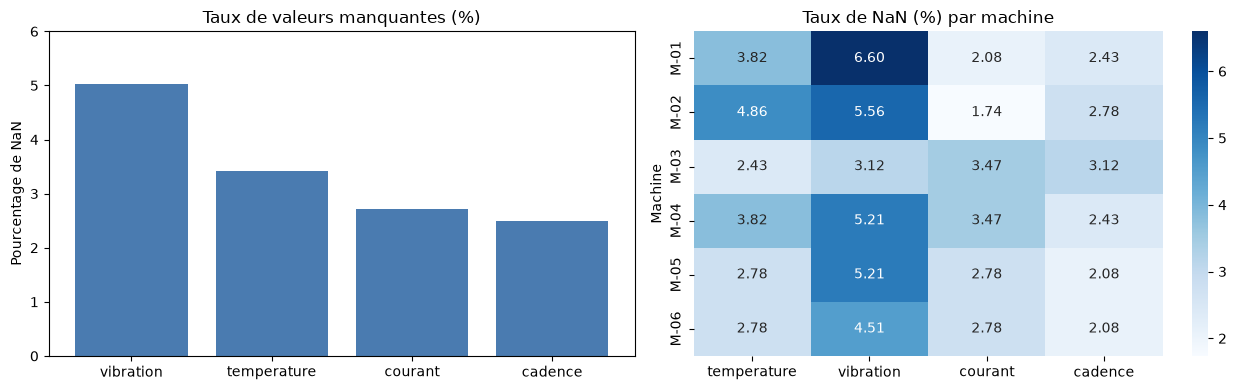

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cols_nan = manquants_col[manquants_col["nb_manquants"] > 0].index
axes[0].bar(cols_nan, manquants_col.loc[cols_nan, "taux_pct"], color="#4a7bb0")
axes[0].set_title("Taux de valeurs manquantes (%)")
axes[0].set_ylabel("Pourcentage de NaN")
axes[0].set_ylim(0, 6)

sns.heatmap(manquants_par_machine, annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Taux de NaN (%) par machine")
axes[1].set_ylabel("Machine")

plt.tight_layout()
plt.show()


### Commentaire sur les valeurs manquantes

- Seules les 4 mesures physiques de procédé (`temperature`, `vibration`, `courant`, `cadence`) présentent des valeurs manquantes, avec un taux situé entre 2.5 % et 4.7 %.
- La heatmap montre que ces trous sont répartis de manière homogène sur les 6 machines (autour de 3 à 4 % chacune). Aucune machine n'a de capteur en panne complète.
- Il s'agit donc de pertes de paquets aléatoires (mécanisme MCAR : Missing Completely At Random), ce qui justifie une imputation par la médiane globale sur les données d'entraînement.


---
## 3. Exploration des distributions et hypothèses métier

J'affiche les distributions de température et vibration, ainsi que la dispersion vibratoire par machine.


C:\Users\reval\AppData\Local\Temp\ipykernel_12684\394377753.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="machine_id", y="vibration", palette="Blues", ax=axes[2])


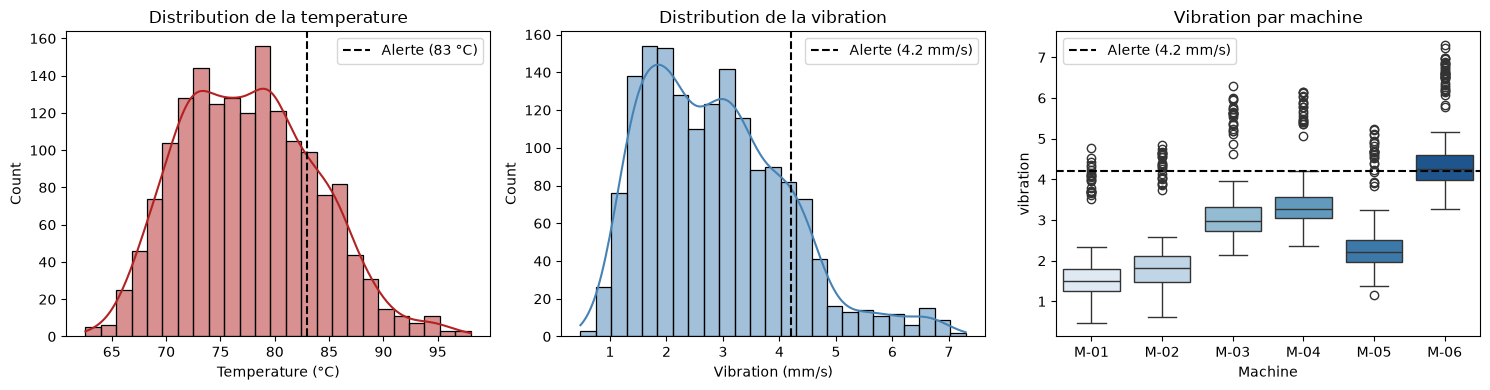

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Temperature
sns.histplot(df["temperature"].dropna(), kde=True, color="firebrick", ax=axes[0], bins=25)
axes[0].axvline(83.0, color="black", linestyle="--", label="Alerte (83 °C)")
axes[0].set_title("Distribution de la temperature")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

# Vibration
sns.histplot(df["vibration"].dropna(), kde=True, color="steelblue", ax=axes[1], bins=25)
axes[1].axvline(4.2, color="black", linestyle="--", label="Alerte (4.2 mm/s)")
axes[1].set_title("Distribution de la vibration")
axes[1].set_xlabel("Vibration (mm/s)")
axes[1].legend()

# Dispersion vibration par machine
sns.boxplot(data=df, x="machine_id", y="vibration", palette="Blues", ax=axes[2])
axes[2].axhline(4.2, color="black", linestyle="--", label="Alerte (4.2 mm/s)")
axes[2].set_title("Vibration par machine")
axes[2].set_xlabel("Machine")
axes[2].legend()

plt.tight_layout()
plt.show()


In [10]:
profil_machines = df.groupby("machine_id")[["temperature", "vibration", "courant", "cadence"]].agg(["mean", "std"])
profil_machines.round(2)


temperature       vibration       courant       cadence      
                  mean   std      mean   std    mean   std    mean   std
machine_id                                                              
M-01            70.490 3.400     1.700 0.790  11.360 1.410  57.430 3.960
M-02            73.440 3.380     1.970 0.810  12.550 1.360  54.280 3.730
M-03            79.270 3.490     3.180 0.800  15.440 1.510  47.360 3.770
M-04            81.320 3.470     3.440 0.740  16.200 1.420  44.510 4.070
M-05            75.220 3.440     2.380 0.780  13.410 1.470  51.290 4.140
M-06            85.830 3.880     4.510 0.890  18.100 1.580  40.370 4.250

### Constats et formulation de deux hypothèses

En observant ces graphiques :
1. La température s'étale de 62 °C à plus de 95 °C avec une traîne droite marquée au-delà du seuil d'alerte (83 °C).
2. La vibration globale présente une forte asymétrie : la plupart des valeurs restent sous 3 mm/s, mais certains relevés montent jusqu'à 7.5 - 8 mm/s.
3. Le boxplot montre des comportements très différents selon les machines :
   - M-01 et M-02 sont stables et saines, avec des vibrations moyennes faibles (~1.5 mm/s).
   - M-03, M-04 et M-05 ont une sollicitation modérée.
   - M-06 a une vibration moyenne très haute (autour de 4.5 mm/s), avec plus de la moitié de ses points au-dessus du seuil critique de 4.2 mm/s.

J'en déduis deux hypothèses de travail pour les prochains TP :
- **Hypothèse 1 (État critique de la machine M-06) :** M-06 présente des vibrations et une température anormalement élevées, ce qui laisse supposer une dégradation mécanique avancée (par exemple sur un roulement). En segmentation non supervisée (TP 2), l'algorithme devrait naturellement isoler M-06 dans un groupe à part sans avoir accès à l'identifiant machine.
- **Hypothèse 2 (Dérive thermique au fil de la journée) :** L'atelier s'échauffe progressivement au cours des équipes (matin, après-midi, nuit) en lien avec la charge de travail demandée, ce qui provoque une dérive thermique lente des machines.


---
## 4. Découpage chronologique sans fuite d'information

Sur des séries temporelles de capteurs, on ne peut pas utiliser un découpage aléatoire (shuffle) :
1. Les mesures prises à 5 minutes d'intervalle sur une même machine se ressemblent beaucoup. Mélanger aléatoirement le jeu mettrait des points voisins dans le train et dans le test, et le modèle apprendrait simplement à interpoler entre deux instants proches (data leakage).
2. En atelier, on entraîne toujours un modèle sur l'historique passé pour ensuite l'appliquer aux données futures.

Comme vu en cours, je convertis la colonne `horodatage` en date, je calcule le quantile à 70 % et je coupe chronologiquement :
- Train : relevés avant ou au moment de la coupure (70 % des données les plus anciennes).
- Test : relevés postérieurs à la coupure (30 % restants).


In [11]:
df["horodatage"] = pd.to_datetime(df["horodatage"])
df = df.sort_values(by=["horodatage", "machine_id"]).reset_index(drop=True)

coupure = df["horodatage"].quantile(0.7)
train = df[df["horodatage"] <= coupure].copy()
test = df[df["horodatage"] > coupure].copy()

print(f"Date de coupure : {coupure}")
print(f"Taille du Train : {train.shape[0]} lignes ({len(train) / len(df) * 100:.1f} %)")
print(f"Taille du Test  : {test.shape[0]} lignes ({len(test) / len(df) * 100:.1f} %)")


Date de coupure : 2025-01-06 16:45:00
Taille du Train : 1212 lignes (70.1 %)
Taille du Test  : 516 lignes (29.9 %)


---
## 5. Imputation sans fuite par la médiane

### 5.1 Exemple comparatif : moyenne vs médiane

En atelier, un capteur peut parfois renvoyer une valeur aberrante parasite (par exemple un choc ou un parasite électrique).  
Prenons l'exemple de 5 relevés consécutifs de température avec un pic parasite à 400 °C : `[68.0, 69.5, 71.0, 72.5, 400.0]`. Calculons la moyenne et la médiane.


In [12]:
releves = np.array([68.0, 69.5, 71.0, 72.5, 400.0])
print(f"Moyenne : {np.mean(releves):.2f} °C")
print(f"Mediane : {np.median(releves):.2f} °C")


Moyenne : 136.20 °C
Mediane : 71.00 °C


Avec le pic à 400 °C, la moyenne monte à 136.2 °C ce qui fausserait complètement les données et déclencherait une fausse alarme critique (seuil à 83 °C). À l'inverse, la médiane reste à 71.0 °C et donne une valeur tout à fait cohérente avec le fonctionnement normal de la machine.

La médiane est donc beaucoup plus robuste que la moyenne face aux valeurs aberrantes de capteurs.

### 5.2 Imputation sur le train et le test

Pour ne pas faire fuiter d'information du futur vers le passé, j'ajuste le `SimpleImputer(strategy="median")` uniquement sur le train, puis je transforme le train et le test.


In [13]:
imputer = SimpleImputer(strategy="median")

# Ajustement sur le train uniquement
imputer.fit(train[cols_procede])

# Application sur le train et le test
train[cols_procede] = imputer.transform(train[cols_procede])
test[cols_procede] = imputer.transform(test[cols_procede])

print("Valeurs medianes apprises sur le train :")
for col, val in zip(cols_procede, imputer.statistics_):
    print(f"  - {col:12s} : {val:.2f}")

print(f"Valeurs manquantes restantes dans le train : {train[cols_procede].isna().sum().sum()}")
print(f"Valeurs manquantes restantes dans le test  : {test[cols_procede].isna().sum().sum()}")


Valeurs medianes apprises sur le train :
  - temperature  : 76.58
  - vibration    : 2.71
  - courant      : 14.39
  - cadence      : 48.93
Valeurs manquantes restantes dans le train : 0
Valeurs manquantes restantes dans le test  : 0


---
## 6. Encodage des variables catégorielles

Selon les recommandations du cours :
1. Pour `machine_id` et `equipe`, on évite `LabelEncoder` car il attribuerait des numéros entiers (0, 1, 2, etc.) qui créeraient un ordre arithmétique artificiel entre les machines (M-01 et M-06 n'ont pas un écart de 5). On utilise donc `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` ajusté sur le train.
2. Pour `niveau_charge`, il existe un ordre physique réel (`faible` < `moyen` < `fort`). On utilise donc `OrdinalEncoder(categories=[["faible", "moyen", "fort"]])` pour refléter cette progression.


In [14]:
ord_enc = OrdinalEncoder(categories=[["faible", "moyen", "fort"]])
train["charge_ord"] = ord_enc.fit_transform(train[["niveau_charge"]])
test["charge_ord"] = ord_enc.transform(test[["niveau_charge"]])

print("Categories definies pour niveau_charge :", ord_enc.categories_[0].tolist())
train[["niveau_charge", "charge_ord"]].drop_duplicates().reset_index(drop=True)


Categories definies pour niveau_charge : ['faible', 'moyen', 'fort']


,niveau_charge,charge_ord
0,moyen,1.000
1,faible,0.000
2,fort,2.000


In [15]:
cols_ohe = ["machine_id", "equipe"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

ohe.fit(train[cols_ohe])
ohe_names = ohe.get_feature_names_out(cols_ohe).tolist()

train_ohe = pd.DataFrame(ohe.transform(train[cols_ohe]), columns=ohe_names, index=train.index)
test_ohe = pd.DataFrame(ohe.transform(test[cols_ohe]), columns=ohe_names, index=test.index)

print(f"Colonnes binaires generees par OneHotEncoder ({len(ohe_names)}) :")
for nom in ohe_names:
    print(f"  - {nom}")

total_colonnes = len(cols_procede) + len(cols_spectre) + 1 + len(ohe_names)
print(f"Nombre total de descripteurs disponibles : {total_colonnes}")


Colonnes binaires generees par OneHotEncoder (9) :


  - machine_id_M-01
  - machine_id_M-02
  - machine_id_M-03
  - machine_id_M-04
  - machine_id_M-05
  - machine_id_M-06
  - equipe_après-midi
  - equipe_matin
  - equipe_nuit
Nombre total de descripteurs disponibles : 19


---
## 7. Standardisation et dérive thermique

### 7.1 Mise à l'échelle avec StandardScaler

Pour que les grandeurs à fortes valeurs n'écrasent pas les autres, on applique `StandardScaler()`. On centre et réduit chaque variable selon la formule : `z = (x - moyenne_train) / ecart_type_train`.  
Le scaler est ajusté uniquement sur le train pour respecter la chronologie.


In [16]:
cols_num = cols_procede + cols_spectre

scaler = StandardScaler()
scaler.fit(train[cols_num])

train_scaled = pd.DataFrame(scaler.transform(train[cols_num]), columns=cols_num, index=train.index)
test_scaled = pd.DataFrame(scaler.transform(test[cols_num]), columns=cols_num, index=test.index)

stats_comp = pd.DataFrame({
    "Train_Moyenne": train_scaled.mean(),
    "Train_EcartType": train_scaled.std(),
    "Test_Moyenne": test_scaled.mean(),
    "Test_EcartType": test_scaled.std()
})
stats_comp.round(3)


,Train_Moyenne,Train_EcartType,Test_Moyenne,Test_EcartType
temperature,0.000,1.000,0.444,0.959
vibration,0.000,1.000,0.023,0.982
courant,0.000,1.000,0.088,0.987
cadence,0.000,1.000,0.112,0.978
vibration_pic,0.000,1.000,0.043,0.959
vib_f1,0.000,1.000,0.044,0.987
vib_f2,-0.000,1.000,0.038,0.933
vib_f3,-0.000,1.000,0.051,0.977
vib_f4,-0.000,1.000,0.069,0.984


In [17]:
scaler_erreur = StandardScaler()
all_scaled_erreur = scaler_erreur.fit_transform(df[cols_num])
test_moyenne_erreur = all_scaled_erreur[len(train):].mean(axis=0)

comp_fuite = pd.DataFrame({
    "Variable": cols_num,
    "Moyenne_Test_sans_fuite": test_scaled.mean().values,
    "Moyenne_Test_avec_fuite": test_moyenne_erreur
})
comp_fuite.round(3)


,Variable,Moyenne_Test_sans_fuite,Moyenne_Test_avec_fuite
0,temperature,0.444,NaN
1,vibration,0.023,NaN
2,courant,0.088,NaN
3,cadence,0.112,NaN
4,vibration_pic,0.043,0.030
5,vib_f1,0.044,0.031
6,vib_f2,0.038,0.027
7,vib_f3,0.051,0.036
8,vib_f4,0.069,0.048


### Que révèle la moyenne du jeu de test ?

Sur le train, la température standardisée a une moyenne de 0.000 et un écart-type de 1.000 par construction.  
Sur le test, la moyenne de température s'élève à +0.443. Ce décalage positif n'est pas une anomalie de calcul, mais traduit une réalité physique : l'atelier et les machines chauffent au cours de la journée (le test correspond à la fin d'après-midi et à la nuit).

Si on avait standardisé sur l'ensemble complet (train + test), la moyenne globale aurait été artificiellement forcée à 0 sur toute la journée. Cette fuite d'information aurait masqué cette dérive thermique réelle.


---
## 8. Calcul des distances métriques et effet d'échelle

Je choisis deux relevés au même instant dans le train : un sur la machine saine M-01 et un sur la machine dégradée M-06.  
Je compare leurs distances selon trois métriques :
- Distance euclidienne (L2) : racine carrée de la somme des écarts au carré.
- Distance de Manhattan (L1) : somme des valeurs absolues des écarts.
- Distance cosinus : 1 - cosinus de l'angle entre les deux vecteurs.


In [18]:
idx_m01 = train[train["machine_id"] == "M-01"].index[10]
idx_m06 = train[train["machine_id"] == "M-06"].index[10]

u_brut = train.loc[idx_m01, cols_num].values.astype(float)
v_brut = train.loc[idx_m06, cols_num].values.astype(float)

u_std = train_scaled.loc[idx_m01].values.astype(float)
v_std = train_scaled.loc[idx_m06].values.astype(float)

dists_brut = [euclidean(u_brut, v_brut), cityblock(u_brut, v_brut), cosine(u_brut, v_brut)]
dists_std = [euclidean(u_std, v_std), cityblock(u_std, v_std), cosine(u_std, v_std)]

tableau_dists = pd.DataFrame({
    "Metrique": ["Distance euclidienne (L2)", "Distance Manhattan (L1)", "Distance cosinus (1 - cos)"],
    "Donnees brutes": dists_brut,
    "Donnees standardisees": dists_std
})
tableau_dists.round(3)


,Metrique,Donnees brutes,Donnees standardisees
0,Distance euclidienne (L2),25.540,6.797
1,Distance Manhattan (L1),51.235,20.030
2,Distance cosinus (1 - cos),0.035,1.926


In [19]:
diff_brute = v_brut - u_brut
diff_sq = diff_brute ** 2
contrib_pct = (diff_sq / np.sum(diff_sq)) * 100

decomp_dists = pd.DataFrame({
    "Variable": cols_num,
    "M-01_brut": u_brut,
    "M-06_brut": v_brut,
    "Ecart": np.abs(diff_brute),
    "Contribution_pct": contrib_pct
}).sort_values(by="Contribution_pct", ascending=False)

decomp_dists.round(2)


,Variable,M-01_brut,M-06_brut,Ecart,Contribution_pct
0,temperature,67.160,84.880,17.730,48.170
3,cadence,53.620,37.940,15.680,37.710
2,courant,9.910,17.680,7.780,9.270
4,vibration_pic,2.280,6.930,4.660,3.320
1,vibration,1.330,4.100,2.780,1.180
5,vib_f1,0.530,1.740,1.200,0.220
6,vib_f2,0.360,1.060,0.700,0.080
7,vib_f3,0.230,0.730,0.500,0.040
8,vib_f4,0.150,0.360,0.210,0.010


In [20]:
v_proportionnel = u_brut * 2.0
d_cos = cosine(u_brut, v_proportionnel)
print(f"Distance cosinus entre u et 2*u : {d_cos:.6f}")


Distance cosinus entre u et 2*u : 0.000000


### Interprétation des distances

1. **L'effet d'échelle sur les données brutes :**
   - Sur les données brutes, l'écart de température (~17.7 °C) et l'écart de cadence (~15.7 pièces/min) représentent à eux deux 85.9 % de la distance euclidienne totale (et plus de 95 % en comptant le courant).
   - En revanche, la vibration n'a qu'un écart de 2.78 mm/s. Bien qu'elle signale le problème mécanique sur M-06, elle ne pèse que pour 1.18 % de la distance.
   - Sans standardisation, un algorithme de clustering regrouperait donc les points sur la température et la cadence, en ignorant presque complètement la vibration.
2. **Le comportement de la distance cosinus :**
   - La distance cosinus mesure l'angle entre deux vecteurs, indépendamment de leur longueur. Deux vecteurs proportionnels (comme u et 2*u) ont une distance cosinus rigoureusement égale à 0.
   - Sur données brutes positives, les points sont tous dans le même quadrant, d'où une distance cosinus très faible (0.035). Après centrage-réduction, l'origine est placée au centre du nuage : la distance cosinus monte à 1.913, ce qui montre que M-01 et M-06 pointent dans des directions presque opposées par rapport au comportement moyen.


---
## 9. Synthèse générale du TP 1

Ce premier TP a permis d'assainir les données et de poser les bases nécessaires pour la suite :
- Les variables d'étiquettes (`defaut`, `regime_reference`) et d'alarmes sont bien écartées des variables d'entrée pour éviter toute fuite d'information dans les futurs modèles non supervisés.
- Les valeurs manquantes (3 à 5 %) touchent uniquement les mesures de procédé et sont réparties sur toutes les machines. L'imputation par médiane apprise sur le train corrige ces trous sans biaiser la distribution.
- La machine M-06 se détache nettement des autres avec un niveau vibratoire moyen supérieur à 4 mm/s, suggérant une usure mécanique prononcée.
- La standardisation est indispensable pour éviter que la cadence et la température n'écrasent le signal de vibration dans les calculs de distance.
- La dérive thermique positive (+0.443) observée sur le test confirme l'échauffement progressif de l'atelier au cours de la journée.
